<a href="https://colab.research.google.com/github/Adri-Ra/K-Means-y-KNN/blob/main/Actividad_KNN_y_KM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Estudiantes aprobados en total: 413 de 500
--- Primeras 5 filas del Dataset ---
   horas_estudio  asistencia  tareas_entregadas  nota_final  aprobado
0       4.996321   84.908086          51.107976   55.095122         0
1       9.605714   76.804818          72.514057   95.045377         1
2       7.855952   65.476381          92.376750   77.186136         1
3       6.789268   90.689751          83.933493   78.298978         1
4       3.248149   84.236559          88.393669   75.879383         1




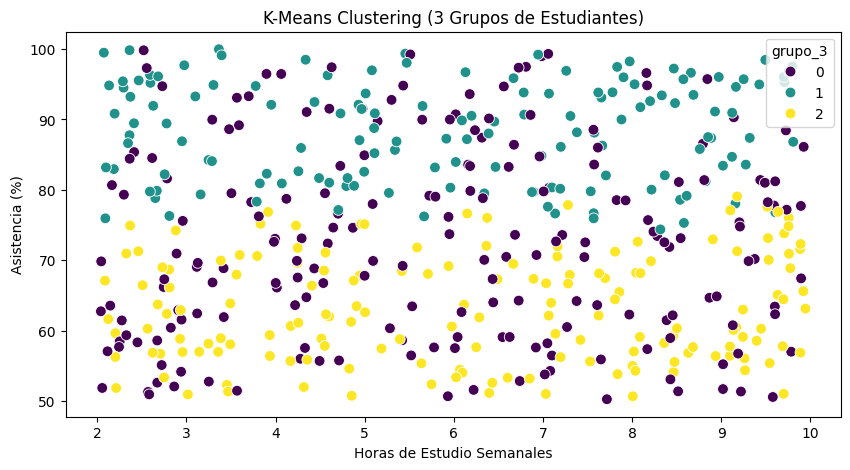

--- Resultados de KNN (K=5) ---
Exactitud (Accuracy): 92.00%

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.76      0.76      0.76        21
           1       0.95      0.95      0.95       104

    accuracy                           0.92       125
   macro avg       0.86      0.86      0.86       125
weighted avg       0.92      0.92      0.92       125


--- Tabla Comparativa de Experimentación con K ---
   Valor de K  Accuracy (Con Normalización)  Accuracy (Sin Normalización)
0           1                         0.936                         0.920
1           3                         0.952                         0.920
2           5                         0.920                         0.912
3           7                         0.920                         0.896
4          11                         0.936                         0.888
5          15                         0.928                         0.888
6          21  

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [1]:
# ==========================================
# ACTIVIDAD: AI Challenge — K-Means y KNN
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. PREPARACIÓN DE DATOS (Dataset equilibrado y realista)
np.random.seed(42) # Para que los datos aleatorios sean reproducibles

n_estudiantes = 500
horas_estudio = np.random.uniform(2, 10, n_estudiantes)
asistencia = np.random.uniform(50, 100, n_estudiantes)
tareas_entregadas = np.random.uniform(40, 100, n_estudiantes)

# Ajustamos la fórmula para que un porcentaje real de estudiantes cruce el umbral de aprobación
nota_final = (horas_estudio * 3.5) + (asistencia * 0.35) + (tareas_entregadas * 0.35) + np.random.normal(0, 4, n_estudiantes)
nota_final = np.clip(nota_final, 0, 100) # Asegurar que esté entre 0 y 100

# Crear la variable objetivo (Aprobado = 1 si nota >= 60, Reprobado = 0 si nota < 60)
aprobado = (nota_final >= 60).astype(int)

# Crear el DataFrame de Pandas
df = pd.DataFrame({
    'horas_estudio': horas_estudio,
    'asistencia': asistencia,
    'tareas_entregadas': tareas_entregadas,
    'nota_final': nota_final,
    'aprobado': aprobado
})

print(f"Estudiantes aprobados en total: {df['aprobado'].sum()} de {n_estudiantes}")
print("--- Primeras 5 filas del Dataset ---")
print(df.head())
print("\n")


# ==========================================
# 2. K-MEANS (Clustering No Supervisado)
# ==========================================

# Seleccionamos las características para agrupar
X_cluster = df[['horas_estudio', 'asistencia', 'tareas_entregadas']]

# K-Means con 3 grupos
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df['grupo_3'] = kmeans_3.fit_predict(X_cluster)

# K-Means con 4 grupos
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
df['grupo_4'] = kmeans_4.fit_predict(X_cluster)

# Visualización de K-Means (3 grupos) usando Horas de Estudio vs Asistencia
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='horas_estudio', y='asistencia', hue='grupo_3', palette='viridis', s=60)
plt.title('K-Means Clustering (3 Grupos de Estudiantes)')
plt.xlabel('Horas de Estudio Semanales')
plt.ylabel('Asistencia (%)')
plt.show()


# ==========================================
# 3. KNN (Clasificación Supervisada)
# ==========================================

# Variables predictoras (X) y variable objetivo (y)
X = df[['horas_estudio', 'asistencia', 'tareas_entregadas']]
y = df['aprobado']

# Dividir en 75% entrenamiento y 25% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Normalización de los datos (Escalado)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Modelo KNN base (con K=5 por defecto)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print("--- Resultados de KNN (K=5) ---")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))


# ==========================================
# 4. EXPERIMENTACIÓN CON DIFERENTES VALORES DE K
# ==========================================

valores_k = [1, 3, 5, 7, 11, 15, 21]
resultados_normalizados = []
resultados_sin_normalizar = []

for k in valores_k:
    # Con datos normalizados
    knn_norm = KNeighborsClassifier(n_neighbors=k)
    knn_norm.fit(X_train_scaled, y_train)
    pred_norm = knn_norm.predict(X_test_scaled)
    resultados_normalizados.append(accuracy_score(y_test, pred_norm))

    # Con datos SIN normalizar
    knn_sin = KNeighborsClassifier(n_neighbors=k)
    knn_sin.fit(X_train, y_train)
    pred_sin = knn_sin.predict(X_test)
    resultados_sin_normalizar.append(accuracy_score(y_test, pred_sin))

# Mostrar tabla de comparación
df_experimento = pd.DataFrame({
    'Valor de K': valores_k,
    'Accuracy (Con Normalización)': resultados_normalizados,
    'Accuracy (Sin Normalización)': resultados_sin_normalizar
})
print("\n--- Tabla Comparativa de Experimentación con K ---")
print(df_experimento)


# ==========================================
# 5. DESAFÍO FINAL: Predicción del caso específico
# ==========================================

# Estudiante de prueba: 4 horas de estudio, 55% asistencia, 50% tareas
estudiante_nuevo = np.array([[4.0, 55.0, 50.0]])

# Es fundamental escalar el nuevo dato usando el mismo scaler entrenado
estudiante_nuevo_scaled = scaler.transform(estudiante_nuevo)

# Predicción con el modelo KNN (usaremos K=5 o el mejor encontrado)
prediccion_desafio = knn.predict(estudiante_nuevo_scaled)
probabilidad_desafio = knn.predict_proba(estudiante_nuevo_scaled)

print("\n--- Resultado del Desafío Final ---")
resultado_texto = "Aprobará" if prediccion_desafio[0] == 1 else "Reprobará"
print(f"El estudiante con 4 hrs de estudio, 55% asistencia y 50% tareas: **{resultado_texto}**")
print(f"Probabilidades [Reprobar, Aprobar]: {probabilidad_desafio[0]}")